# Reference building and query mapping

This tutorial covers the basic scPoli workflow with scpolivi:

1. train a **reference** model on several studies;
2. **map a query** dataset onto it (scArches surgery: only new condition embeddings are learned);
3. **transfer cell-type labels** with an uncertainty score;
4. look at the joint embedding, the prototypes and the condition embeddings.

It follows the scArches scPoli surgery tutorial, so results can be compared with scArches.

**Data.** Human pancreas, 16,382 cells from 9 studies, 4,000 genes
([figshare](https://figshare.com/ndownloader/files/41581626)). Seven studies form the
reference and the two CEL-Seq studies the query. All **alpha cells are removed from the
reference**, so the query contains a cell type the reference has never seen. A good model
should flag those cells as uncertain instead of forcing them into a known type.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

from scpolivi import SCPOLI

warnings.filterwarnings("ignore")
scvi.settings.seed = 0                      # reproducible weights, splits and sampling
scvi.settings.verbosity = logging.WARNING   # less console output
sc.set_figure_params(figsize=(4.5, 4.5), frameon=False, dpi=80)

## Data

In [2]:
DATA = "data/pancreas_sparse.h5ad"   # path to the downloaded file
adata = sc.read(DATA)
adata

AnnData object with n_obs × n_vars = 16382 × 4000
    obs: 'study', 'cell_type'
    layers: None (.X)

In [3]:
pd.crosstab(adata.obs.cell_type, adata.obs.study)

study,celseq,celseq2,fluidigmc1,inDrop1,inDrop2,inDrop3,inDrop4,smarter,smartseq2
cell_type,,,,,,,,,
acinar,228,274,21,110,3,843,2,0,188
activated_stellate,19,90,16,51,81,100,52,0,55
alpha,191,843,239,236,676,1130,284,886,1008
beta,161,445,258,872,371,787,495,472,308
delta,50,203,25,214,125,161,101,49,127
ductal,327,258,36,120,301,376,280,0,444
endothelial,5,21,14,130,23,92,7,0,21
epsilon,1,4,1,13,2,2,1,0,8
gamma,18,110,18,70,86,36,63,85,213


In [4]:
reference_studies = ["inDrop1", "inDrop2", "inDrop3", "inDrop4", "fluidigmc1", "smartseq2", "smarter"]
query_studies = ["celseq", "celseq2"]

reference = adata[adata.obs.study.isin(reference_studies)].copy()
reference = reference[reference.obs.cell_type != "alpha"].copy()   # held-out cell type
query = adata[adata.obs.study.isin(query_studies)].copy()
print(f"reference: {reference.n_obs} cells, query: {query.n_obs} cells")

reference: 8634 cells, query: 3289 cells


## Reference model

`setup_anndata` registers which `obs` columns are conditions and which are labels. Here
`study` is the only condition key and `cell_type` the only label level. Several of each are
possible; see the next tutorial.

In [5]:
SCPOLI.setup_anndata(reference, condition_keys="study", cell_type_keys="cell_type")
model = SCPOLI(reference, embedding_dims=5, recon_loss="nb")
model

SCPOLI model: conditions ['study'] [7], cell types ['cell_type'] (13 prototypes), hidden [64], latent 10, 
recon_loss nb
Training status: Not Trained
Model's adata is minified?: False

Training runs in two phases. During the first `pretraining_epochs`, only the conditional VAE
is trained. After that, the prototype loss (weight `eta`) pulls labeled cells towards the
centroid of their cell type. Early stopping only starts after pretraining. The settings
match the scArches tutorial.

In [6]:
early_stopping = {
    "early_stopping_metric": "val_prototype_loss",
    "mode": "min",
    "threshold": 0,
    "patience": 20,
    "reduce_lr": True,
    "lr_patience": 13,
    "lr_factor": 0.1,
}
model.train(n_epochs=50, pretraining_epochs=40, eta=5, early_stopping_kwargs=early_stopping)

Epoch 50/50: 100%|██████████| 50/50 [01:06<00:00,  1.32s/it, v_num=1, train_loss=1.09e+3]


`model.history` stores the per-epoch losses. The prototype loss is zero during pretraining and
drops quickly once it is switched on.

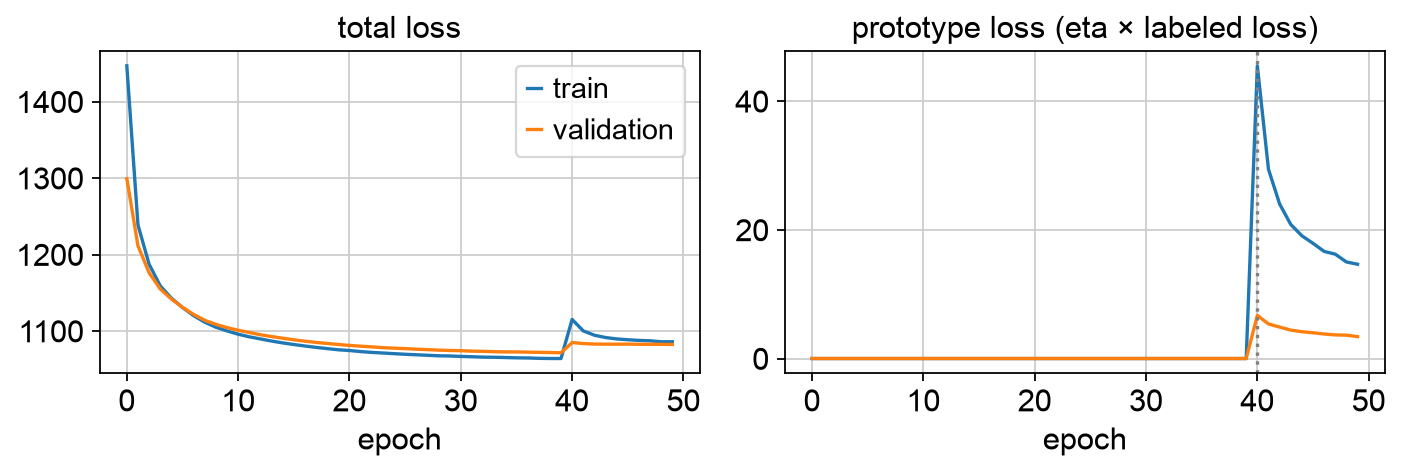

In [7]:
h = model.history
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(h["train_loss"], label="train")
axes[0].plot(h["validation_loss"], label="validation")
axes[0].set(title="total loss", xlabel="epoch")
axes[0].legend()
axes[1].plot(h["prototype_loss_train"], label="train")
axes[1].plot(h["prototype_loss_validation"], label="validation")
axes[1].axvline(40, color="grey", ls=":")
axes[1].set(title="prototype loss (eta × labeled loss)", xlabel="epoch")
plt.tight_layout()

The reference latent space: studies are mixed and cell types separated.

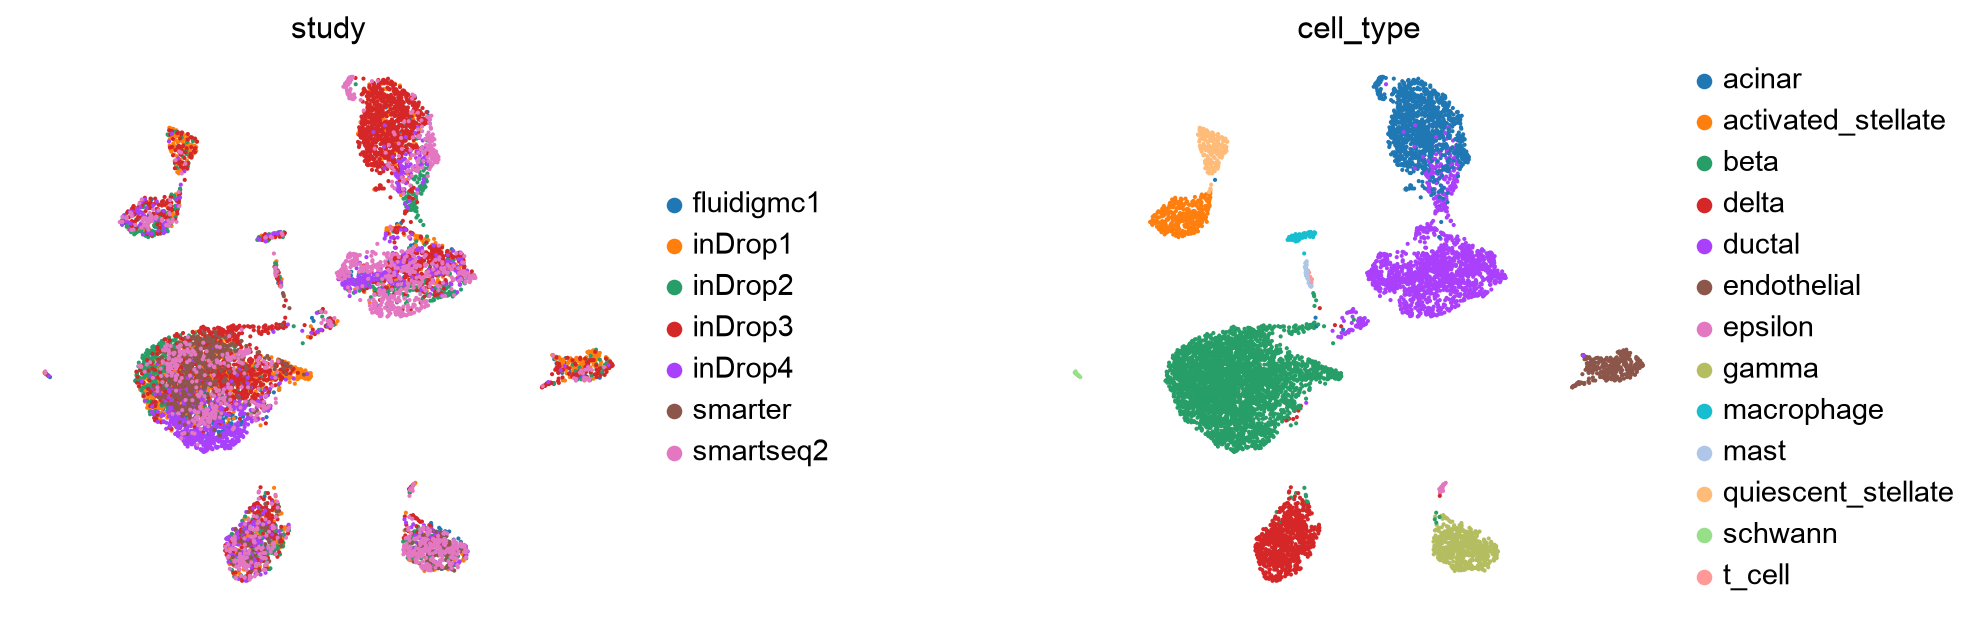

In [8]:
reference.obsm["X_scpoli"] = model.get_latent(mean=True)
sc.pp.neighbors(reference, use_rep="X_scpoli")
sc.tl.umap(reference)
sc.pl.umap(reference, color=["study", "cell_type"], wspace=0.5)

In [9]:
model.save("results/tutorials/reference_model", overwrite=True, save_anndata=True)

## Query mapping

`load_query_data` copies the reference model and adds an embedding for each new study. With
the default `freeze=True`, only these embeddings (and the dispersion parameters) are trained,
so the reference latent space stays as it is. `labeled_indices=[]` means that no query labels
are used for training; here they are only used to evaluate the result.

In [10]:
query_model = SCPOLI.load_query_data(query, reference_model=model, labeled_indices=[])
query_model.train(n_epochs=50, pretraining_epochs=40, eta=10)

Epoch 50/50: 100%|██████████| 50/50 [00:24<00:00,  2.03it/s, v_num=1, train_loss=1.49e+3]


In [11]:
query_model.save("results/tutorials/query_model", overwrite=True, save_anndata=True)

## Label transfer

`classify` assigns each cell to its nearest labeled prototype. It returns, per cell-type
level, the predictions (`preds`) and an uncertainty score (`uncert`, rescaled to [0, 1] with
`scale_uncertainties=True`). We use `use_mean=True`, which classifies the posterior mean of
each cell's latent code and is more accurate than scArches' default of classifying a random
sample.

In [12]:
result = query_model.classify(query, scale_uncertainties=True, use_mean=True)["cell_type"]
query.obs["predicted"] = result["preds"]
query.obs["uncertainty"] = result["uncert"]

known = query.obs.cell_type != "alpha"
print("accuracy on known cell types:",
      round(accuracy_score(query.obs.cell_type[known], query.obs.predicted[known]), 4))
print("macro F1 on known cell types:",
      round(f1_score(query.obs.cell_type[known], query.obs.predicted[known], average="macro"), 4))

accuracy on known cell types: 0.9792
macro F1 on known cell types: 0.8785


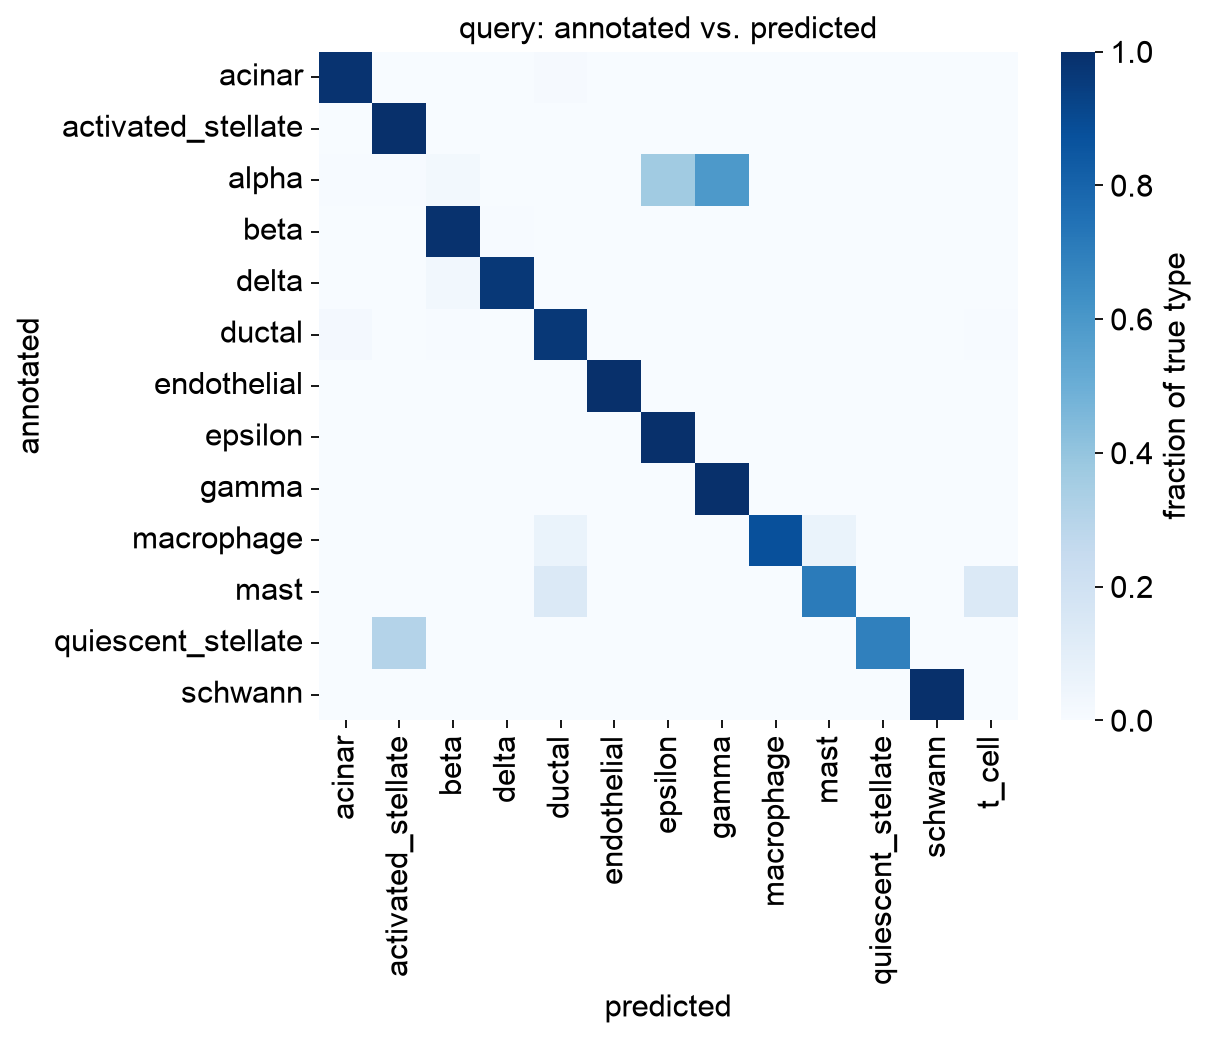

In [13]:
conf = pd.crosstab(query.obs.cell_type, query.obs.predicted, normalize="index")
plt.figure(figsize=(7, 5.5))
plt.grid(False)
sns.heatmap(conf, cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "fraction of true type"})
plt.xlabel("predicted")
plt.ylabel("annotated")
plt.title("query: annotated vs. predicted");

The alpha cells have no matching prototype, so they are assigned to some other type. Their
uncertainty is much higher than that of known types, which is how unseen populations are
detected:

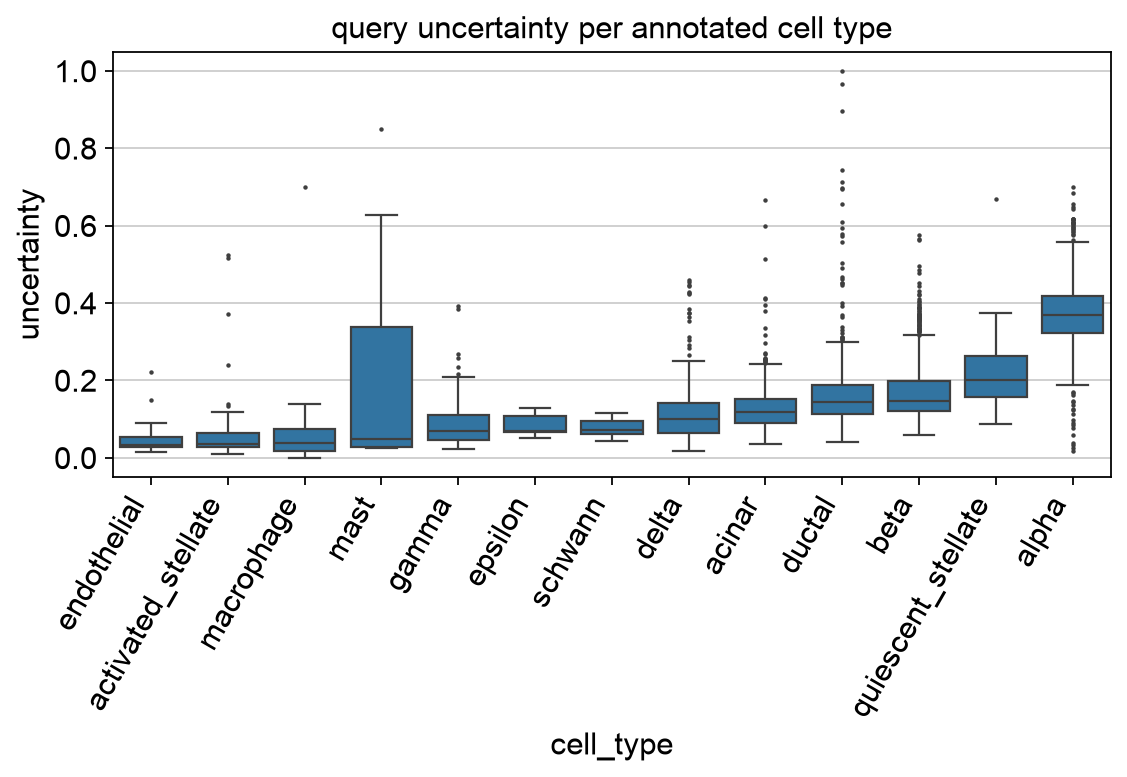

In [14]:
order = query.obs.groupby("cell_type", observed=True)["uncertainty"].median().sort_values().index
plt.figure(figsize=(8, 3.5))
sns.boxplot(data=query.obs, x="cell_type", y="uncertainty", order=order, fliersize=1)
plt.xticks(rotation=60, ha="right")
plt.title("query uncertainty per annotated cell type");

## Joint embedding of reference and query

The query model knows all studies, so it embeds reference and query cells together.

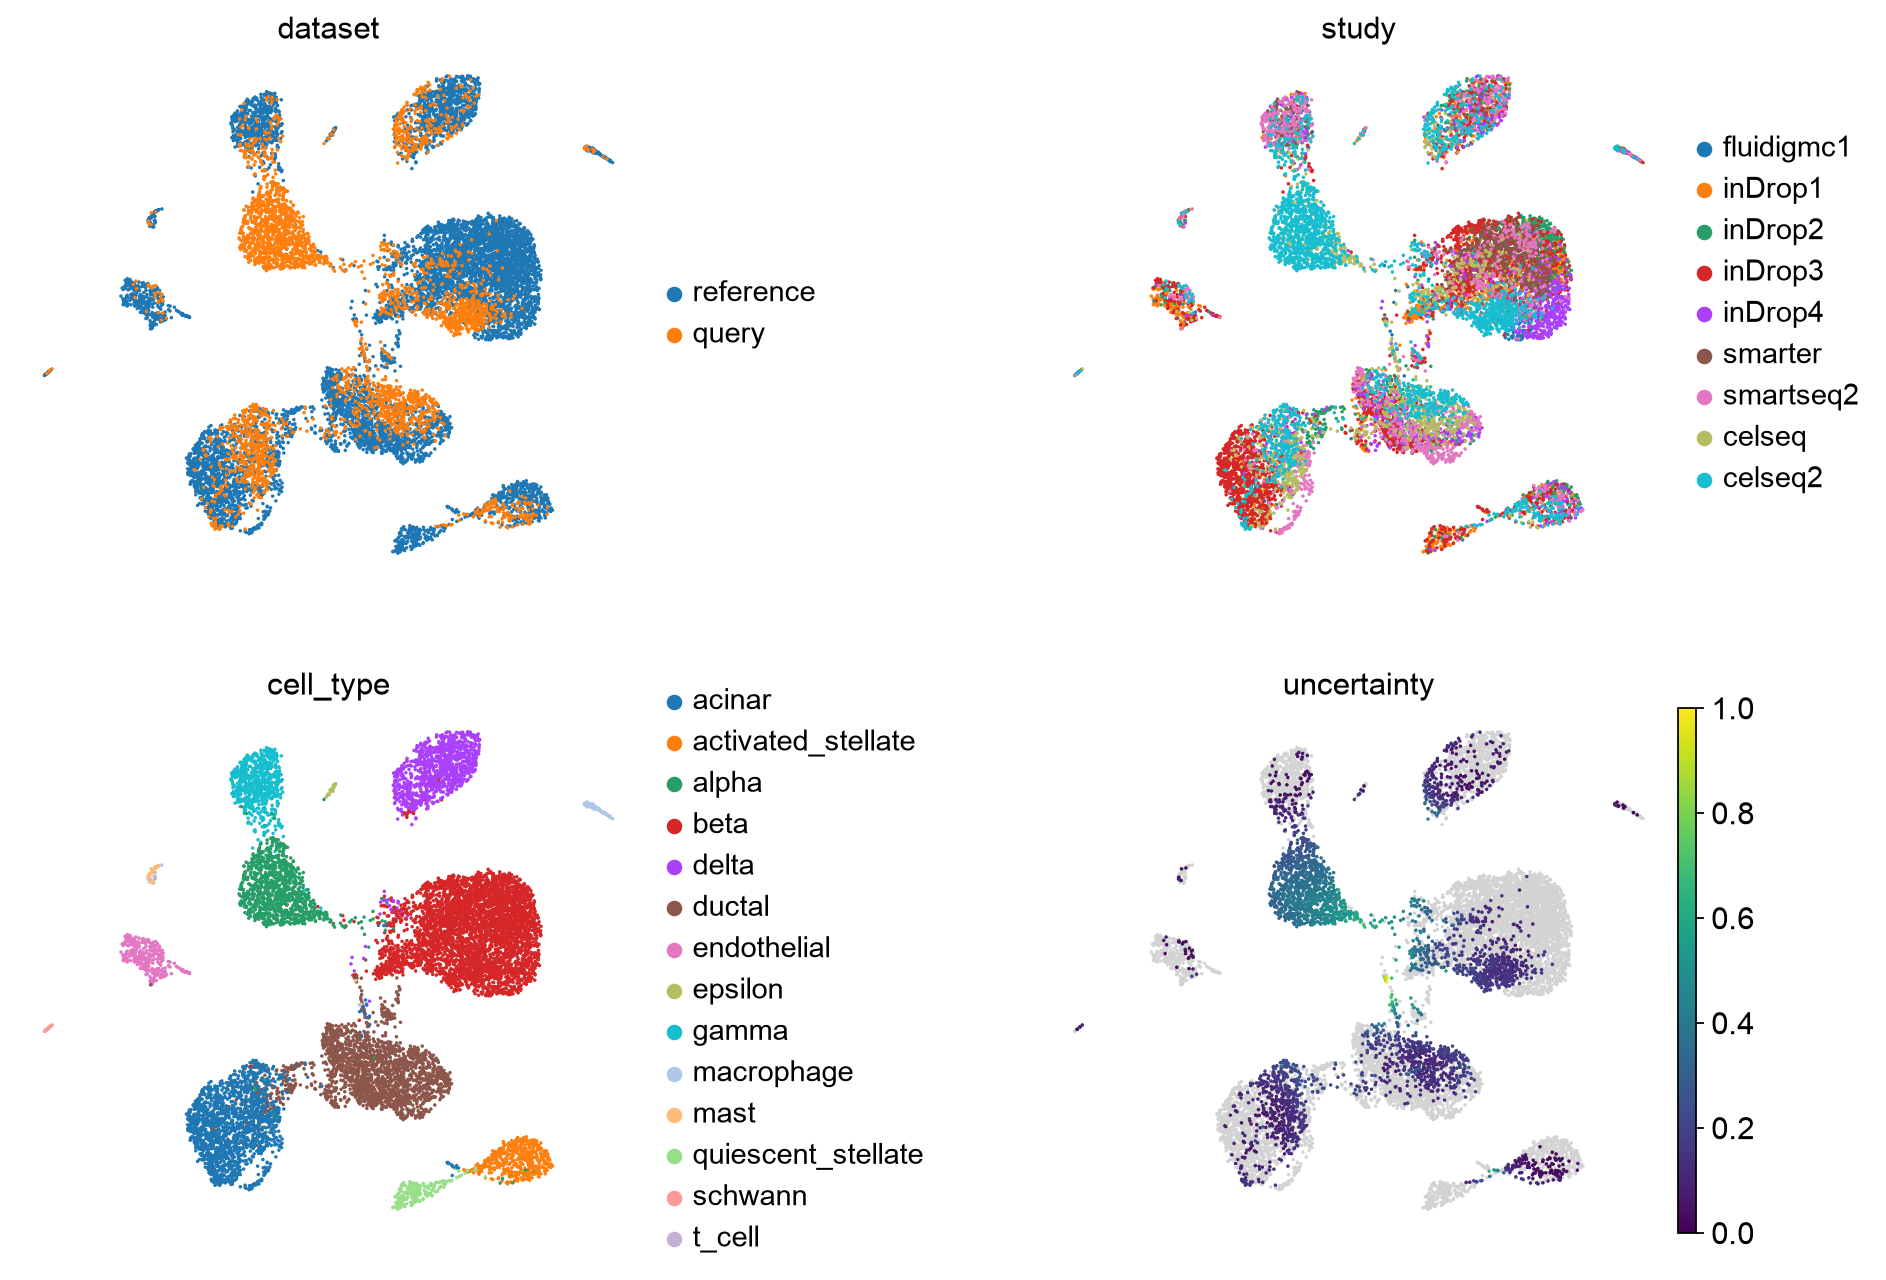

In [15]:
joint = sc.concat([reference, query], label="dataset", keys=["reference", "query"])
joint.obsm["X_scpoli"] = query_model.get_latent(joint, mean=True)
joint.obs["uncertainty"] = np.nan
joint.obs.loc[query.obs_names, "uncertainty"] = query.obs["uncertainty"].values
sc.pp.neighbors(joint, use_rep="X_scpoli")
sc.tl.umap(joint)
sc.pl.umap(joint, color=["dataset", "study", "cell_type", "uncertainty"], ncols=2, wspace=0.5)

## Prototypes and condition embeddings

`get_prototypes_info` returns the prototypes as an AnnData, so they can be projected together
with the cells. Each labeled prototype is classified as its own cell type.

In [16]:
protos = query_model.get_prototypes_info("labeled")
protos.obs[["cell_type", "cell_type_pred", "cell_type_uncert"]]

,cell_type,cell_type_pred,cell_type_uncert
0,gamma,gamma,0.0
1,acinar,acinar,0.0
2,delta,delta,0.0
3,beta,beta,0.0
4,ductal,ductal,0.0
5,endothelial,endothelial,0.0
6,activated_stellate,activated_stellate,0.0
7,schwann,schwann,0.0
8,mast,mast,0.0
9,macrophage,macrophage,0.0


Each study is a learned vector, so studies can be compared directly. In this run the four
inDrop studies group together, and the two CEL-Seq query studies sit next to each other.

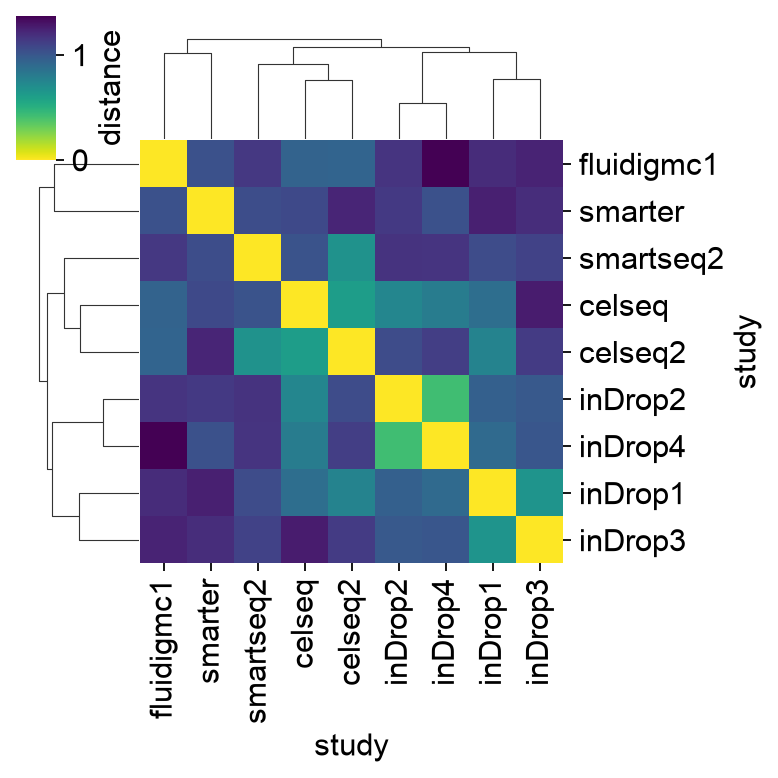

In [17]:
emb = query_model.get_conditional_embeddings()
dist = pd.DataFrame(
    np.linalg.norm(emb.X[:, None] - emb.X[None], axis=-1),
    index=emb.obs_names, columns=emb.obs_names,
)
with plt.rc_context({"axes.grid": False}):
    sns.clustermap(dist, cmap="viridis_r", figsize=(5, 5), cbar_kws={"label": "distance"});